# Axelrod Culture Model – Phase-Plot Notebook

This notebook implements the Axelrod model of cultural dissemination, and explores the phase space of the number of traits \(q\) vs. parameter \(B\) (or another parameter of interest, such as density or feature count) by running many simulations and generating a heatmap of normalized number of culture domains in the absorbing state.

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from mesa import Agent, Model
from mesa.space import MultiGrid
from mesa.time import RandomActivation
from mesa.datacollection import DataCollector
from tqdm import tqdm
import multiprocessing as mp
from joblib import Parallel, delayed


In [2]:
# CultureAgent implements the Axelrod cultural dissemination rule.
# Each agent has F features; each feature holds a trait in {0,…,q−1}.
class CultureAgent(Agent):
    def __init__(self, unique_id, model, features, q):
        super().__init__(unique_id, model)
        # Store the agent's feature vector and trait cardinality.
        # features: list of length F, values in [0, q-1].
        self.features = features
        self.q = q

    def similarity(self, other):
        # Fraction of matching features between self and other.
        return sum(1 for a,b in zip(self.features, other.features) if a==b) / len(self.features)

    def step(self):
        # Interact with one von Neumann neighbour (moore=False => N,S,E,W).
        # include_center=False excludes self from the neighbor list.
        neighbours = self.model.grid.get_neighbors(self.pos, moore=False, include_center=False)
        if not neighbours:
            return  # No interaction possible this turn.

        # Pick a random neighbour and compute cultural similarity.
        neighbour = random.choice(neighbours)
        sim = self.similarity(neighbour)
        # With probability equal to similarity, adopt one differing trait.
        if sim > 0 and random.random() < sim:
            # Find indices of features that differ.
            diffs = [i for i,(a,b) in enumerate(zip(self.features, neighbour.features)) if a!=b]
            if diffs:
                # Choose a differing feature and copy the neighbour's trait.
                i = random.choice(diffs)
                self.features[i] = neighbour.features[i]

## CultureAgent: Axelrod Interaction Rule

This cell defines the agent-level dynamics for the Axelrod model of cultural dissemination. Each agent carries a feature vector of length `F`, where each feature takes one of `q` possible traits. At every step, an agent:

- Samples one von Neumann neighbour (north/south/east/west).
- Computes similarity as the fraction of matching features.
- With probability equal to that similarity, copies exactly one differing feature from the neighbour.

This homophily-based rule (higher overlap ⇒ more likely to interact) drives local convergence while potentially sustaining global diversity across the lattice.

In [3]:
class AxelrodModel(Model):
    def __init__(self, width, height, N, F, q, B):
        super().__init__()
        self.grid = MultiGrid(width, height, torus=False)   #multiple agents can occupy single cell
        self.schedule = RandomActivation(self)
        self.F = F
        self.q = q
        self.B = B
        # create agents
        for i in range(N):
            x = random.randrange(width)
            y = random.randrange(height)
            feats = [random.randrange(q) for _ in range(F)]
            a = CultureAgent(i, self, feats, q)
            self.grid.place_agent(a, (x,y))
            self.schedule.add(a)
        self.datacollector = DataCollector(
            model_reporters={"NumCultures": lambda m: self.count_culture_domains()},
            agent_reporters={}
        )

    def count_culture_domains(self):
        # simple method: count distinct feature‐vectors among agents
        feats = [tuple(agent.features) for agent in self.schedule.agents]
        return len(set(feats))

    def step(self):
        self.schedule.step()
        self.datacollector.collect(self)

    #def run_until_absorbed(self, max_steps=10000):
    #    """does agent have a neighbour"""
    #    for step in range(max_steps):
    #        active_agents = [a for a in self.schedule.agents if len(self.grid.get_neighbors(a.pos, moore=False, include_center=False)) > 0]
    #        if not active_agents:
    #            break
    #        self.step()
    #    return self.count_culture_domains()

    def has_active_interactions(self):
        for agent in self.schedule.agents:
            neighbours = self.grid.get_neighbors(agent.pos, moore=False, include_center=False)
            for neighbour in neighbours:
                sim = agent.similarity(neighbour)
                if 0 < sim < 1:
                    return True
        return False

    def run_until_absorbed(self, max_steps=10000):
        for step in range(max_steps):
            if not self.has_active_interactions():
                break
            self.step()
        return self.count_culture_domains()


Running simulations: 100%|██████████| 1595/1595 [02:06<00:00, 12.60it/s]


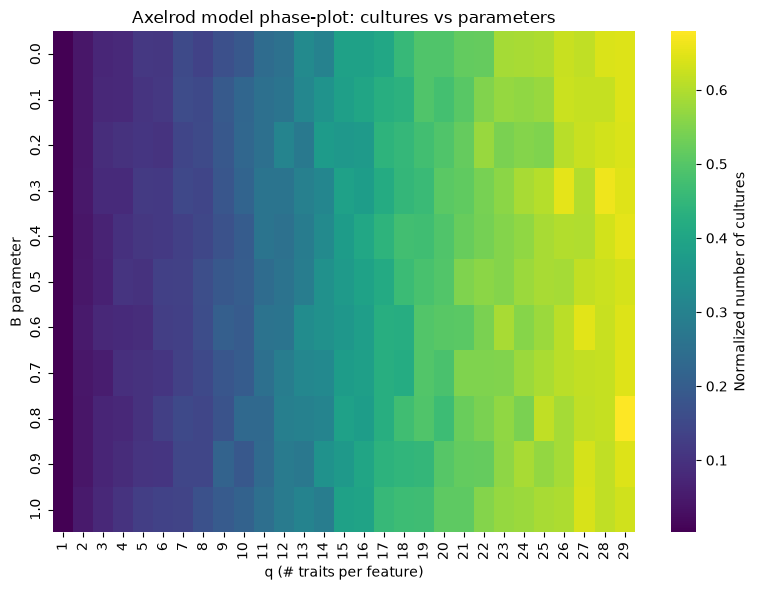

In [6]:
# --- Simulation parameters ---
qs = np.arange(1, 30, 1)       # trait diversity
Bs = np.arange(0.0, 1.1, 0.1)  # placeholder bias parameter
runs_per_cell = 5 #10
max_steps = 500 #2000
width, height, N, F = 20, 20, 400, 5


# --- Function to run one simulation ---
def run_one_simulation(B, q, max_steps):
    try:
        m = AxelrodModel(width=width, height=height, N=N, F=F, q=q, B=B)
        num_cultures = m.run_until_absorbed(max_steps=max_steps)
        living_agents = len(m.schedule.agents)
        if living_agents == 0:
            num_cultures = 0
        return num_cultures
    except Exception:
        raise


# --- Create all parameter combinations ---
tasks = [(B, q) for B in Bs for q in qs for _ in range(runs_per_cell)]

# --- Run in parallel with progress bar ---
results = Parallel(n_jobs=mp.cpu_count()-2, backend="loky")(
    delayed(run_one_simulation)(B, q, max_steps)
    for B, q in tqdm(tasks, desc="Running simulations")
)

# --- Reshape results into 3D array [B, q, runs] ---
results = np.array(results).reshape(len(Bs), len(qs), runs_per_cell)
heat = np.mean(results, axis=2) / N  # normalize by population size

# --- Plot heatmap ---
plt.figure(figsize=(8, 6))
sns.heatmap(
    heat,
    xticklabels=qs,
    yticklabels=np.round(Bs, 2),
    cmap="viridis",
    cbar_kws={'label': 'Normalized number of cultures'}
)
plt.xlabel("q (# traits per feature)")
plt.ylabel("B parameter")
plt.title("Axelrod model phase-plot: cultures vs parameters")
plt.tight_layout()
plt.show()

Running simulations (varying q & F): 100%|██████████| 2900/2900 [10:27<00:00,  4.62it/s] 


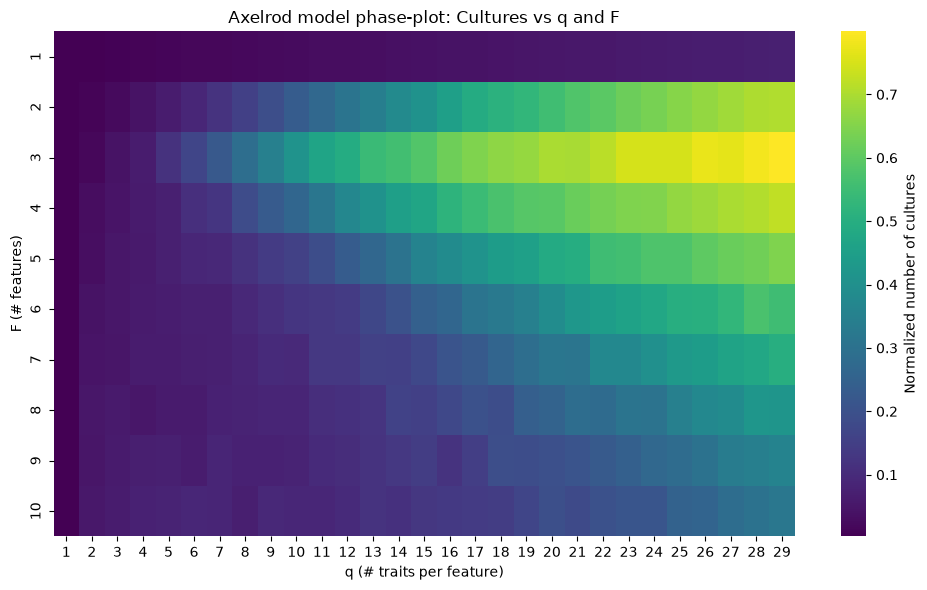

In [ ]:
# --- Simulation parameters ---
qs = np.arange(1, 30, 1)       # number of traits per feature
Fs = np.arange(1, 11, 1)       # number of features
B = 0.5                        # fixed bias parameter
runs_per_cell = 5 #10
max_steps = 2000
width, height, N = 20, 20, 400

# --- Function to run one simulation ---
def run_one_simulation(F, q, max_steps):
    try:
        m = AxelrodModel(width=width, height=height, N=N, F=F, q=q, B=B)
        num_cultures = m.run_until_absorbed(max_steps=max_steps)
        living_agents = len(m.schedule.agents)
        if living_agents == 0:
            num_cultures = 0
        return num_cultures
    except Exception:
        return 0

# --- Create all parameter combinations ---
tasks = [(F, q) for F in Fs for q in qs for _ in range(runs_per_cell)]

# --- Run in parallel with progress bar ---
results = Parallel(n_jobs=mp.cpu_count()-2, backend="loky")(
    delayed(run_one_simulation)(F, q, max_steps)
    for F, q in tqdm(tasks, desc="Running simulations (varying q & F)")
)

# --- Reshape results into 3D array [F, q, runs] ---
results = np.array(results).reshape(len(Fs), len(qs), runs_per_cell)
heat = np.mean(results, axis=2) / N  # normalize by population size

# --- Plot heatmap ---
plt.figure(figsize=(10, 6))
sns.heatmap(
    heat,
    xticklabels=qs,
    yticklabels=Fs,
    cmap="viridis",
    cbar_kws={'label': 'Normalized number of cultures'}
)
plt.xlabel("q (# traits per feature)")
plt.ylabel("F (# features)")
plt.title("Axelrod model phase-plot: Cultures vs q and F")
plt.tight_layout()
plt.show()

Heatmap shows  
q increases -> less overlap with neighbors -> less interaction -> less exchange -> more fragmentation

- F=1: just one culture
- F=2: more cultures
- F=3: maximum number of cultures (most cultural diversity / fragmentation)
- F>3: fragmentation decreases
